---

# **Project Details**

**Author**: Sai Gavaskar Sakalam

**Date**: August 24, 2026

**Program**: UT Austin – Post Graduate Program in Artificial Intelligence & Machine Learning

**Project**: HelmNet

---

# **Problem Statement**

## **Business Context**

On construction sites and in factories, a worker without a safety helmet is at serious risk of head injury. Checking helmet compliance by hand does not scale and is easy to get wrong on large sites. An image model that flags workers without helmets can make safety checks faster and more reliable.

## **Objective**

Build an image classifier that labels each image as one of two classes:

- **With Helmet** – the worker is wearing a safety helmet
- **Without Helmet** – the worker is not wearing a safety helmet

## **Data Description**

The dataset has **4,125 images**: 3,161 **with helmet** and 964 **without helmet**.

The images come from construction sites, factories and other industrial settings, with different lighting, camera angles, worker poses and activities (standing, using tools, moving).

# **Installing and Importing the Necessary Libraries**

In [1]:
!pip install tensorflow[and-cuda] scikit-learn==1.6.1 opencv-python==4.12.0.88 seaborn==0.13.2 matplotlib==3.10.0 numpy==2.0.2 pandas==2.2.2 -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.9/18.9 MB 41.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 108.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user



**Note:** after the install cell finishes, restart the runtime (Colab) or kernel (Jupyter), then run the rest of the notebook from the next cell.

**About the imports below:** `numpy`/`pandas` handle the image array and labels, `matplotlib`/`seaborn`/`cv2` are used for visualization, the `tensorflow.keras` imports provide the layers, optimizers and the pretrained VGG-16 model used to build the four classifiers, `sklearn` provides the train/validation/test split, class-weight computation and evaluation metrics, and `google.colab` is used to mount Google Drive and display images.

In [2]:
# On Google Colab: mount Drive and point the data path to your Drive folder.
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import math
import cv2

import keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications.vgg16 import VGG16
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, recall_score, precision_score, classification_report
from sklearn.metrics import mean_squared_error as mse
from google.colab.patches import cv2_imshow

import warnings
warnings.filterwarnings('ignore')

In [3]:
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print(tf.__version__)

Num GPUs Available: 1
2.20.0



In [4]:
# 1. Set Python random seed
random.seed(812)

# 2. Set NumPy random seed
np.random.seed(812)

# 3. Set TensorFlow seed (covers Keras + backend)
tf.keras.utils.set_random_seed(812)

# 4. Enable deterministic GPU ops (if using GPU)
tf.config.experimental.enable_op_determinism()

# **Data Overview**

## Loading the data

Mount Google Drive and point `DATA_DIR` at the folder that contains `images.npy` and `labels.csv` (update the path below to match where the files were uploaded).

In [6]:
# On Google Colab: mount Drive and point the data path to your Drive folder.
DATA_DIR = 'data/'

images = np.load(os.path.join(DATA_DIR, 'images.npy'))
labels_df = pd.read_csv(os.path.join(DATA_DIR, 'labels.csv'))

print(images.shape)
print(images.dtype)
print(labels_df.shape)
print(labels_df['label'].value_counts())

(4125, 200, 200, 3)
uint8
(4125, 1)
label
1    3161
0     964
Name: count, dtype: int64



**Observations:**

- The image array holds 4125 images, each 200 x 200 pixels with 3 colour channels (RGB), stored as `uint8` (pixel values 0-255).
- The labels file has exactly one row per image (4125 rows) with a single `label` column: `1` = With Helmet, `0` = Without Helmet.
- The two files line up 1:1 by row order, so `images[i]` corresponds to `labels_df.loc[i, 'label']`.

# **Exploratory Data Analysis**

### Plot random images from each of the classes and print their corresponding labels.

Without Helmet -> indices: [32, 406, 628, 930, 732] | labels: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
With Helmet -> indices: [2173, 2404, 3606, 4092, 2122] | labels: [np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1)]



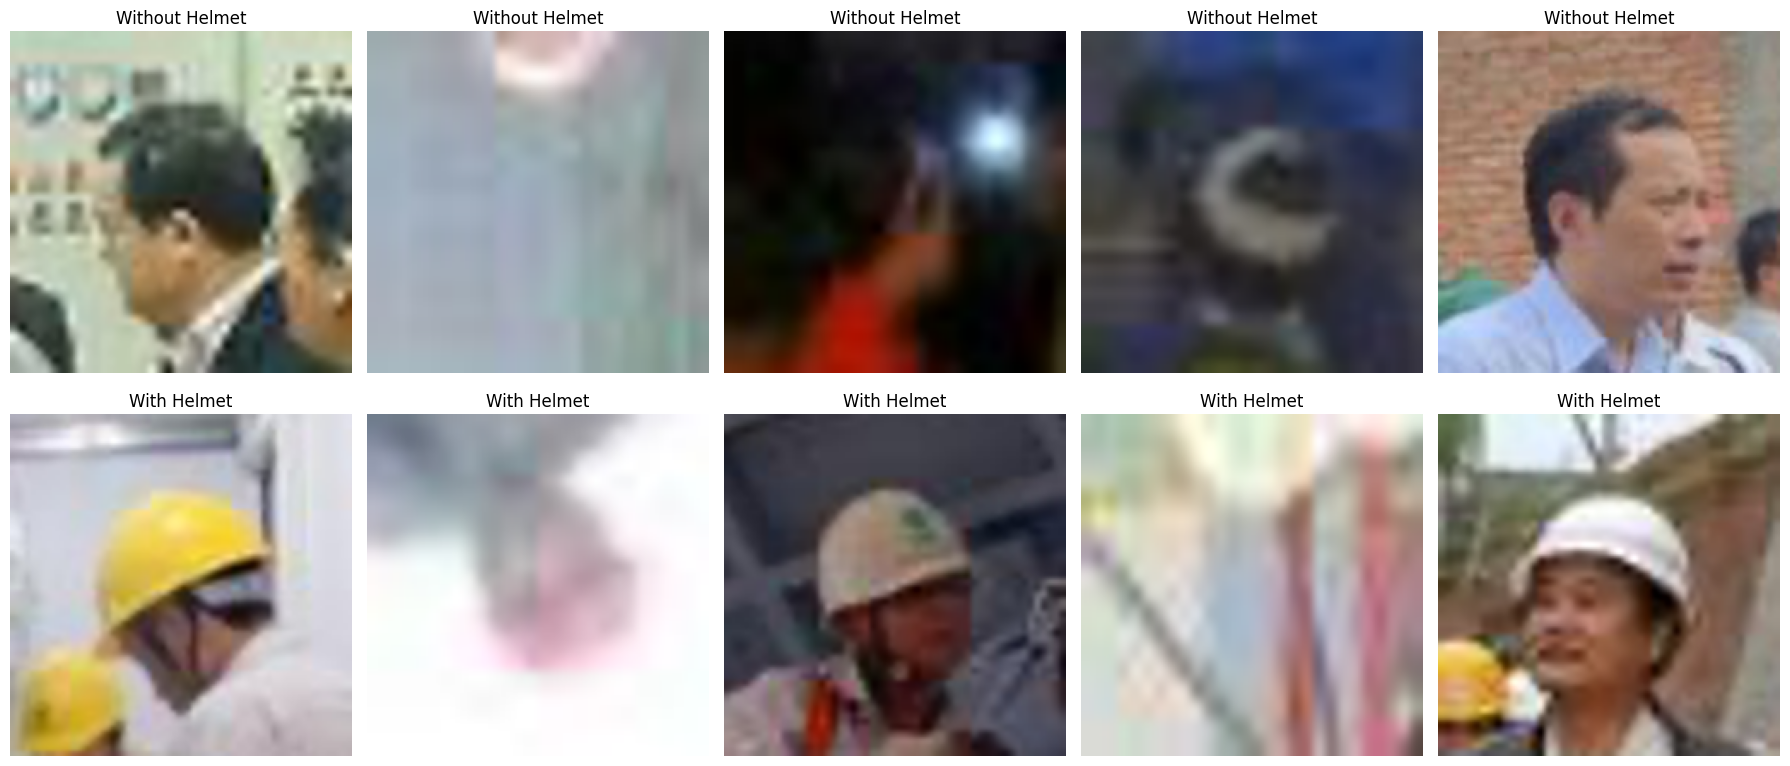

In [7]:
# Map numeric labels to readable class names for titles/printing
class_names = {0: 'Without Helmet', 1: 'With Helmet'}

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for row, class_label in enumerate(class_names):
    # Pick 5 random image indices belonging to this class
    class_indices = labels_df[labels_df['label'] == class_label].index
    sample_indices = random.sample(list(class_indices), 5)

    # Explicitly print each sampled image's index and label
    print(class_names[class_label], '-> indices:', list(sample_indices), '| labels:', [labels_df.loc[idx, 'label'] for idx in sample_indices])

    for col, idx in enumerate(sample_indices):
        axes[row, col].imshow(images[idx])
        axes[row, col].set_title(class_names[class_label])
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

## Checking for class imbalance

label
With Helmet       3161
Without Helmet     964
Name: count, dtype: int64
label
With Helmet       76.63
Without Helmet    23.37
Name: count, dtype: float64



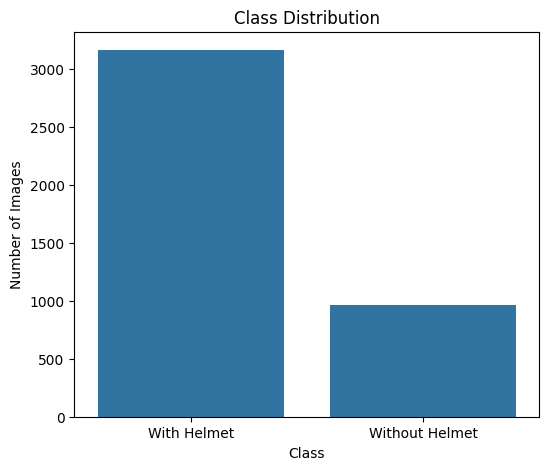

In [8]:
# Count images per class and rename index to readable class names
class_counts = labels_df['label'].value_counts().rename(index=class_names)

print(class_counts)
print((class_counts / class_counts.sum() * 100).round(2))

# Visualize the class distribution
plt.figure(figsize=(6, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.ylabel('Number of Images')
plt.xlabel('Class')
plt.title('Class Distribution')
plt.show()

**Key meaningful observations from EDA:**

- With Helmet: 3161 images (76.6%); Without Helmet: 964 images (23.4%) — a clear class imbalance of roughly 3.3:1.
- Because of this imbalance, accuracy alone can be misleading: a model that always predicts "With Helmet" would already score ~76.6% accuracy while catching zero real safety violations. Recall on the "Without Helmet" class, and class-weighting during training, are used later in this notebook to guard against this.
- All images are already a uniform 200 x 200 x 3, so no resizing is required before modeling.
- The sampled images show real-world variation in lighting, camera angle, and worker pose/activity, and some images are blurry or tightly cropped around the face — this is the kind of variation the model needs to generalize across, which is also the motivation for using data augmentation in Model 4.

# **Data Preprocessing**

### Splitting the dataset

In [9]:
y = labels_df['label']

# First split off a held-out test set (15%), stratified to keep the same class ratio in every split
X_train, X_temp, y_train, y_temp = train_test_split(images, y, test_size=0.3, stratify=y, random_state=812)
# Split the remaining 30% evenly into validation (15%) and test (15%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=812)

# Free the full image array now that train/val/test copies exist
del images

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts())
print(y_val.value_counts())
print(y_test.value_counts())

(2887, 200, 200, 3) (619, 200, 200, 3) (619, 200, 200, 3)
label
1    2212
0     675
Name: count, dtype: int64
label
1    474
0    145
Name: count, dtype: int64
label
1    475
0    144
Name: count, dtype: int64



### Data Normalization

In [10]:
# Scale pixel values from 0-255 to 0-1 for stable gradient-based training
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

### Handling Class Imbalance

Since "With Helmet" images outnumber "Without Helmet" images roughly 3 to 1 (see EDA), class weights are computed from the training labels below and passed to every model in this notebook, so that mistakes on the minority "Without Helmet" class are penalized more heavily during training.

In [11]:
# Compute weights inversely proportional to class frequency so the minority
# "Without Helmet" class is not drowned out during training
class_weights_array = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights_array))

print(class_weight_dict)

{0: np.float64(2.1385185185185187), 1: np.float64(0.6525768535262206)}



# **Model Building**

## **Model Evaluation Criterion**

In this business context, failing to flag a worker who is **not** wearing a helmet (a false negative on the "Without Helmet" class) is far costlier than a false alarm, since it directly risks an undetected safety violation. Accuracy alone is also unreliable here because the classes are imbalanced (76.6% With Helmet vs. 23.4% Without Helmet).

For this reason, every model below is evaluated on **Accuracy, Precision, Recall and F1-score**, with particular attention paid to **Recall on the "Without Helmet" class** — the metric that best reflects how many real safety violations the model would actually catch.

## Utility Functions

Five helper functions are defined below and reused for every model in this notebook:

- `model_performance_classification` returns overall Accuracy, Recall, Precision and F1-score for a model on a given set of images/labels. Note that because it uses micro-averaging, its Recall/Precision/F1 values work out to be equal to Accuracy for this binary task — it is kept here since it was provided, but per-class performance is what actually matters for this problem.
- `print_classification_report` prints per-class Precision/Recall/F1, which is how the "Without Helmet" recall that matters most for this business problem is actually read off.
- `plot_confusion_matrix` plots the confusion matrix for a model on a given set of images/labels.
- `plot_learning_curves` plots the training vs. validation loss and accuracy curves from a model's training history, used to check for over/underfitting.
- `visualize_predictions` shows a random grid of images together with their actual and predicted class.

In [12]:
def model_performance_classification(model, predictors, target):
    # Threshold the sigmoid output at 0.5 to get a class prediction
    pred = model.predict(predictors).reshape(-1) > 0.5
    target = target.to_numpy().reshape(-1)

    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred, average='micro')
    precision = precision_score(target, pred, average='micro')
    f1 = f1_score(target, pred, average='micro')

    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1}, index=[0])

    return df_perf

In [13]:
def plot_confusion_matrix(model, predictors, target, ml=False):
    pred = model.predict(predictors).reshape(-1) > 0.5
    target = target.to_numpy().reshape(-1)

    # Renamed to `cm` so this local variable doesn't shadow the imported confusion_matrix function
    cm = tf.math.confusion_matrix(target, pred)
    f, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax,
        xticklabels=['Without Helmet', 'With Helmet'],
        yticklabels=['Without Helmet', 'With Helmet']
    )
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

In [14]:
def print_classification_report(model, predictors, target):
    # Per-class precision/recall/F1 - this is where "Without Helmet" recall is actually visible
    pred = model.predict(predictors).reshape(-1) > 0.5
    target = target.to_numpy().reshape(-1)
    print(classification_report(target, pred, target_names=['Without Helmet', 'With Helmet']))

In [15]:
def plot_learning_curves(history):
    # Side-by-side loss and accuracy curves to visually check for over/underfitting
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Train Loss')
    axes[0].plot(history.history['val_loss'], label='Validation Loss')
    axes[0].set_title('Loss')
    axes[0].legend()

    axes[1].plot(history.history['accuracy'], label='Train Accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[1].set_title('Accuracy')
    axes[1].legend()

    plt.show()

In [16]:
def visualize_predictions(model, X, y, n=10):
    # Sample n random images and compare actual vs predicted class side by side
    indices = random.sample(range(len(X)), n)
    preds = (model.predict(X[indices]).reshape(-1) > 0.5).astype(int)
    actuals = y.to_numpy()[indices]

    fig, axes = plt.subplots(2, 5, figsize=(18, 8))
    for ax, idx, pred, actual in zip(axes.flatten(), indices, preds, actuals):
        ax.imshow(X[idx])
        ax.set_title(f"Actual: {class_names[actual]}\nPredicted: {class_names[pred]}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Model 1: Convolutional Neural Network (CNN) from Scratch

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 200, 200, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 80000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    10,240,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 10,334,401 (39.42 MB)

Trainable params: 10,333,953 (39.42 MB)

Non-trainable params: 448 (1.75 KB)

Epoch 1/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 19s 120ms/step - accuracy: 0.8476 - loss: 0.5445 - val_accuracy: 0.2342 - val_loss: 4.8314
Epoch 2/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.9096 - loss: 0.2342 - val_accuracy: 0.2359 - val_loss: 5.2083
Epoch 3/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 114ms/step - accuracy: 0.9328 - loss: 0.1640 - val_accuracy: 0.3134 - val_loss: 3.9605
Epoch 4/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.9546 - loss: 0.1127 - val_accuracy: 0.7754 - val_loss: 0.6985
Epoch 5/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.9640 - loss: 0.0912 - val_accuracy: 0.7738 - val_loss: 0.7178
Epoch 6/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.9761 - loss: 0.0679 - val_accuracy: 0.8853 - val_loss: 0.3555
Epoch 7/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.9789 - loss: 0.0584 - val_accuracy: 0.8966 - val_loss: 0.3269
Epoch 8/25
91/91 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - accuracy: 0.9747 - loss: 0.0537 - val_accu

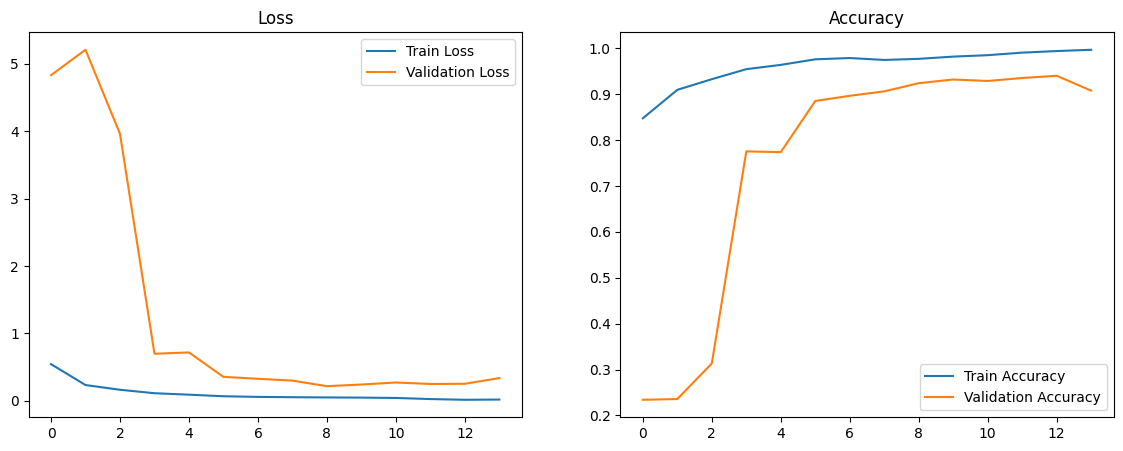

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step
   Accuracy  Recall  Precision  F1 Score
0    0.9761  0.9761     0.9761    0.9761
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.924071  0.924071   0.924071  0.924071
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
                precision    recall  f1-score   support

Without Helmet       0.82      0.86      0.84       145
   With Helmet       0.96      0.94      0.95       474

      accuracy                           0.92       619
     macro avg       0.89      0.90      0.90       619
  weighted avg       0.93      0.92      0.92       619

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step



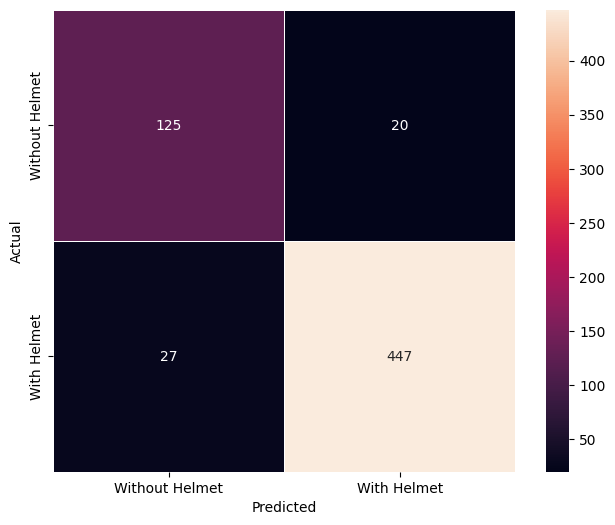

In [17]:
model1 = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(200, 200, 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(1, activation='sigmoid')
])

model1.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0001), metrics=['accuracy'])

model1.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history1 = model1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

plot_learning_curves(history1)

print(model_performance_classification(model1, X_train, y_train))
print(model_performance_classification(model1, X_val, y_val))
print_classification_report(model1, X_val, y_val)
plot_confusion_matrix(model1, X_val, y_val)

**Configuration:** loss = `binary_crossentropy`, optimizer = `Adam(learning_rate=1e-4)`, epochs = 25 (with `EarlyStopping`, patience=5), batch\_size = 32. A low learning rate and early stopping are used because this model trains every layer from scratch and is the most likely of the four to overfit.

**Observations:**

- This is the only model learning all of its visual features from scratch on ~2,900 training images, so it is the most prone to overfitting of the four models here — check the gap between the train and validation curves above.
- Look specifically at the Recall for the "Without Helmet" class in the classification report — that is the number that matters most for the safety use case, not overall accuracy.
- If validation performance is noticeably weaker than training performance, this model will likely be outperformed by the transfer-learning models below, which start from ImageNet features instead of learning edges/textures/shapes from zero.

### Visualizing the predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step



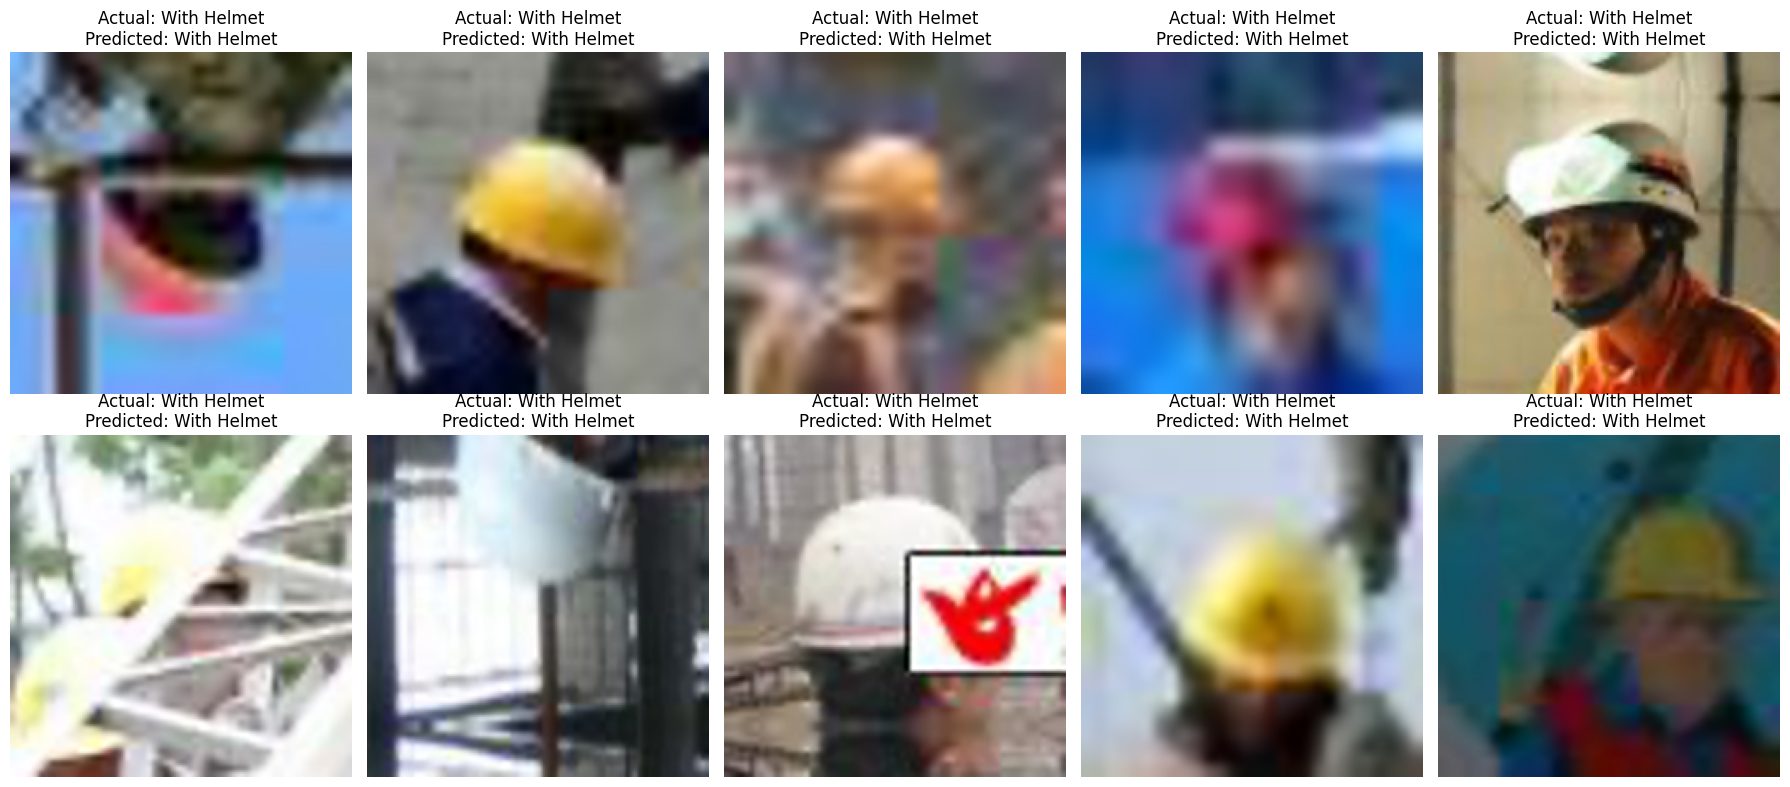

In [18]:
visualize_predictions(model1, X_val, y_val)

## Model 2: Transfer Learning with VGG-16 (Base)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        18,433 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 14,733,121 (56.20 MB)

Trainable params: 18,433 (72.00 KB)

Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 17s 164ms/step - accuracy: 0.6211 - loss: 0.5977 - val_accuracy: 0.7011 - val_loss: 0.5476
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 17s 183ms/step - accuracy: 0.7534 - loss: 0.4819 - val_accuracy: 0.7625 - val_loss: 0.4755
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 153ms/step - accuracy: 0.8026 - loss: 0.4249 - val_accuracy: 0.7932 - val_loss: 0.4339
Epoch 4/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 150ms/step - accuracy: 0.8268 - loss: 0.3881 - val_accuracy: 0.8158 - val_loss: 0.4061
Epoch 5/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 17s 184ms/step - accuracy: 0.8389 - loss: 0.3616 - val_accuracy: 0.8320 - val_loss: 0.3855
Epoch 6/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 13s 148ms/step - accuracy: 0.8507 - loss: 0.3410 - val_accuracy: 0.8352 - val_loss: 0.3693
Epoch 7/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.8580 - loss: 0.3243 - val_accuracy: 0.8417 - val_loss: 0.3561
Epoch 8/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 150ms/step - accuracy: 0.8656 - loss: 0.3102 - val_accu

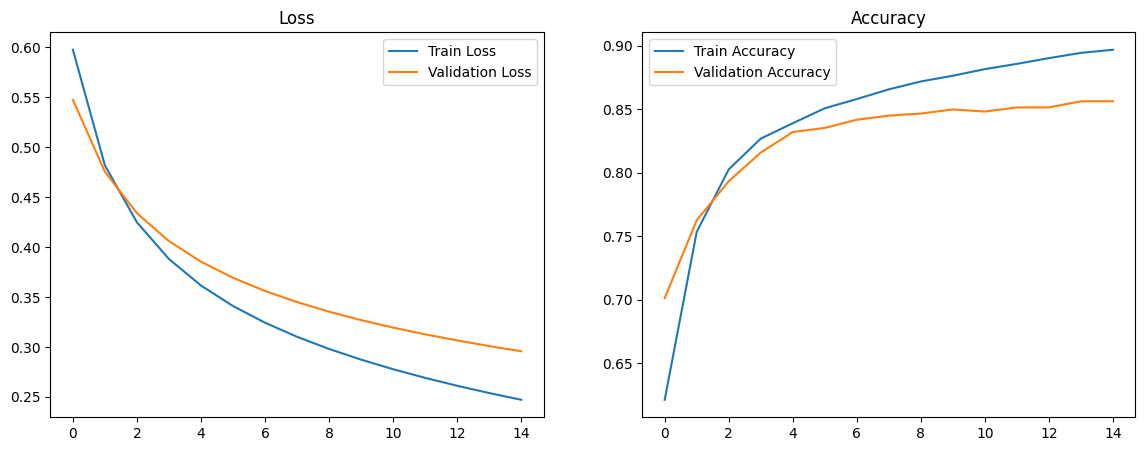

91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.903706  0.903706   0.903706  0.903706
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
   Accuracy   Recall  Precision  F1 Score
0   0.85622  0.85622    0.85622   0.85622
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
                precision    recall  f1-score   support

Without Helmet       0.64      0.88      0.74       145
   With Helmet       0.96      0.85      0.90       474

      accuracy                           0.86       619
     macro avg       0.80      0.87      0.82       619
  weighted avg       0.88      0.86      0.86       619

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step



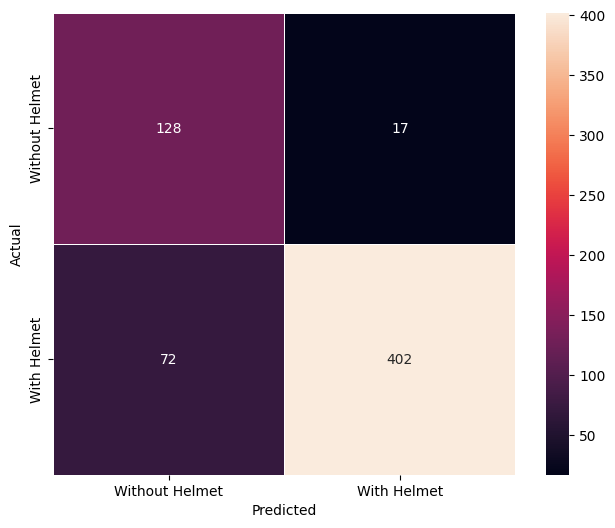

In [19]:
base_model_2 = VGG16(weights='imagenet', include_top=False, input_shape=(200, 200, 3))

for layer in base_model_2.layers:
    layer.trainable = False

model2 = Sequential([
    base_model_2,
    Flatten(),
    Dense(1, activation='sigmoid')
])

model2.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0001), metrics=['accuracy'])

model2.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history2 = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

plot_learning_curves(history2)

print(model_performance_classification(model2, X_train, y_train))
print(model_performance_classification(model2, X_val, y_val))
print_classification_report(model2, X_val, y_val)
plot_confusion_matrix(model2, X_val, y_val)

**Configuration:** loss = `binary_crossentropy`, optimizer = `Adam(learning_rate=1e-4)`, epochs = 15 (with `EarlyStopping`), batch\_size = 32. Fewer epochs are needed than Model 1 since only the final Dense layer is being trained on top of frozen, already-useful ImageNet features.

**Observations:**

- This model reuses VGG-16's ImageNet-pretrained convolutional layers (frozen) as a fixed feature extractor, with a single Dense output layer on top — no extra hidden (FFNN) layers.
- Because the convolutional base already encodes strong general-purpose visual features, this model typically needs far fewer epochs than the scratch CNN to reach a good validation score, and is less prone to overfitting since only the final Dense layer is being trained.
- With only one Dense layer, the model has limited capacity to combine those features — compare its validation Recall/F1 above to Model 3 (which adds a hidden FFNN layer) to see whether that extra capacity actually helps here.

### Visualizing the predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step



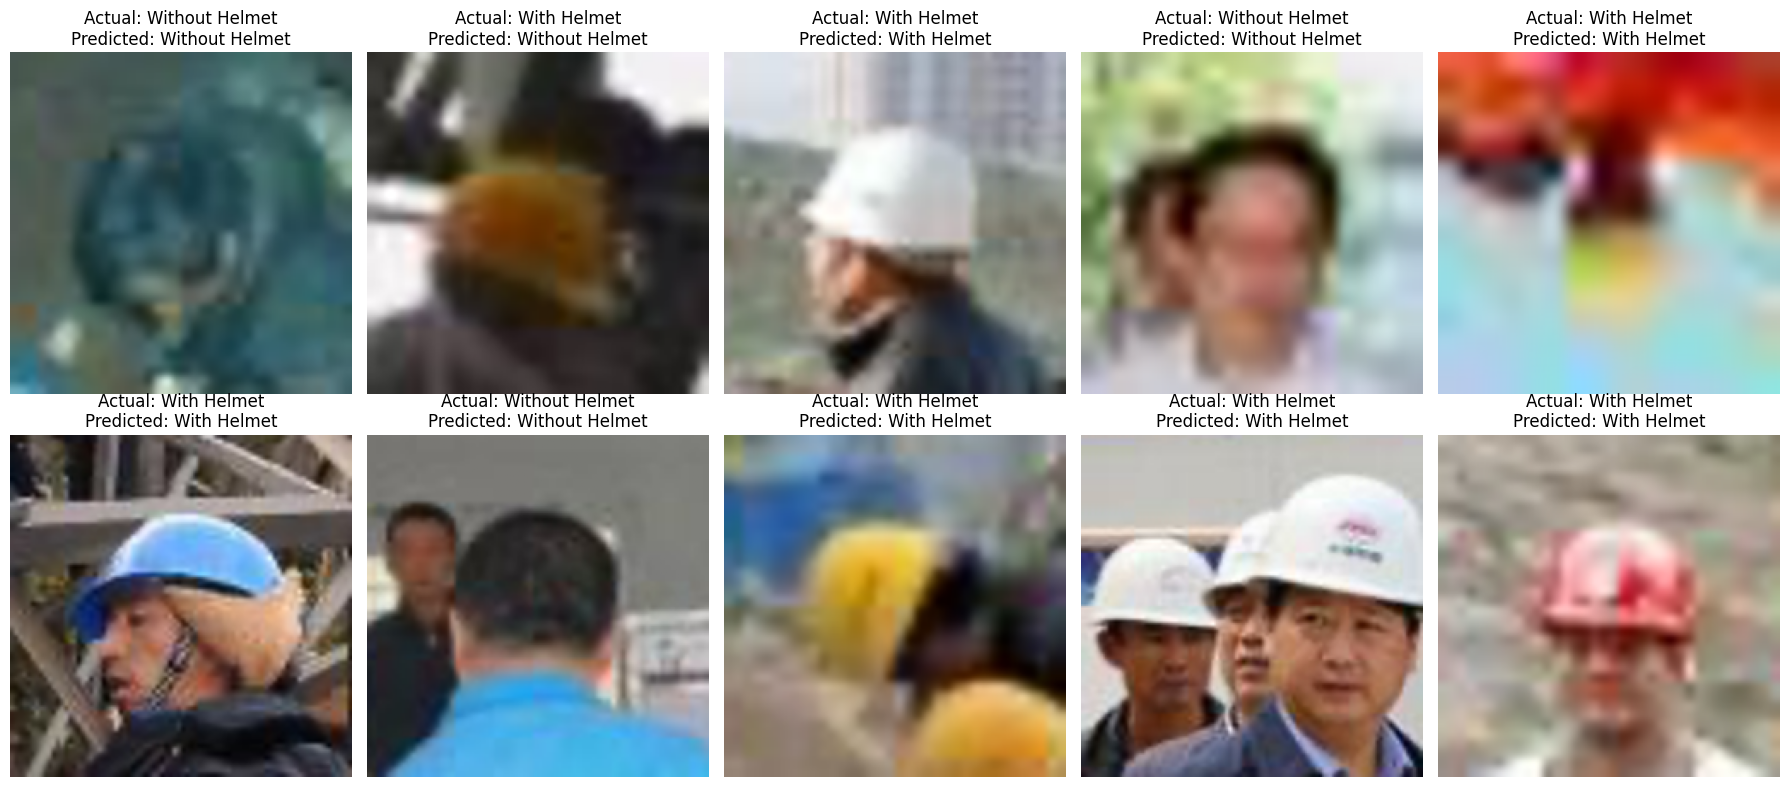

In [20]:
visualize_predictions(model2, X_val, y_val)

## Model 3: Transfer Learning with VGG-16 (Base + FFNN)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 19,433,793 (74.13 MB)

Trainable params: 4,719,105 (18.00 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 17s 164ms/step - accuracy: 0.7593 - loss: 0.4594 - val_accuracy: 0.8239 - val_loss: 0.3622
Epoch 2/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 159ms/step - accuracy: 0.8521 - loss: 0.3007 - val_accuracy: 0.8724 - val_loss: 0.2999
Epoch 3/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 154ms/step - accuracy: 0.8857 - loss: 0.2457 - val_accuracy: 0.9015 - val_loss: 0.2248
Epoch 4/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 151ms/step - accuracy: 0.9030 - loss: 0.2196 - val_accuracy: 0.9095 - val_loss: 0.2213
Epoch 5/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.9089 - loss: 0.2014 - val_accuracy: 0.9144 - val_loss: 0.2157
Epoch 6/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 148ms/step - accuracy: 0.9186 - loss: 0.1771 - val_accuracy: 0.9128 - val_loss: 0.2063
Epoch 7/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - accuracy: 0.9307 - loss: 0.1650 - val_accuracy: 0.9160 - val_loss: 0.2046
Epoch 8/15
91/91 ━━━━━━━━━━━━━━━━━━━━ 14s 151ms/step - accuracy: 0.9297 - loss: 0.1600 - val_accu

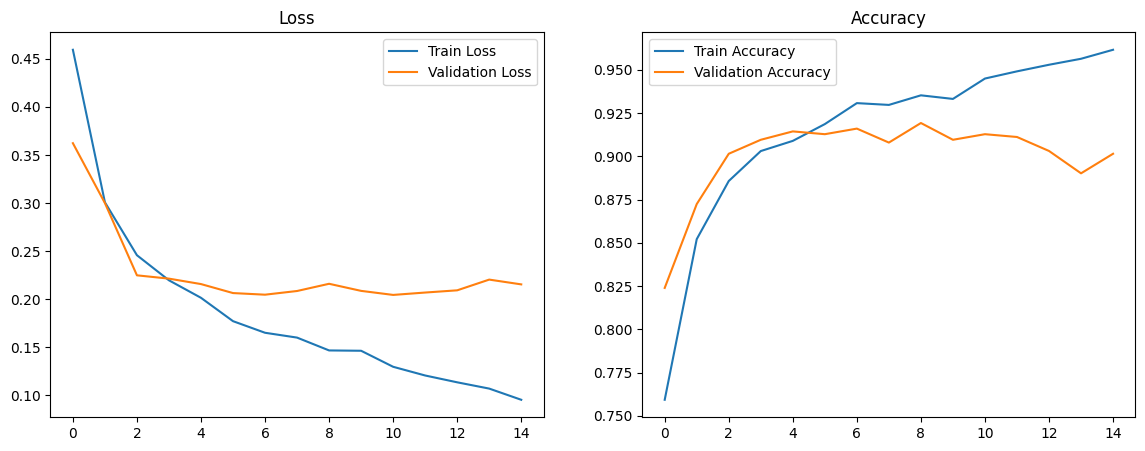

91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.975407  0.975407   0.975407  0.975407
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.912763  0.912763   0.912763  0.912763
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step
                precision    recall  f1-score   support

Without Helmet       0.83      0.79      0.81       145
   With Helmet       0.94      0.95      0.94       474

      accuracy                           0.91       619
     macro avg       0.88      0.87      0.88       619
  weighted avg       0.91      0.91      0.91       619

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step



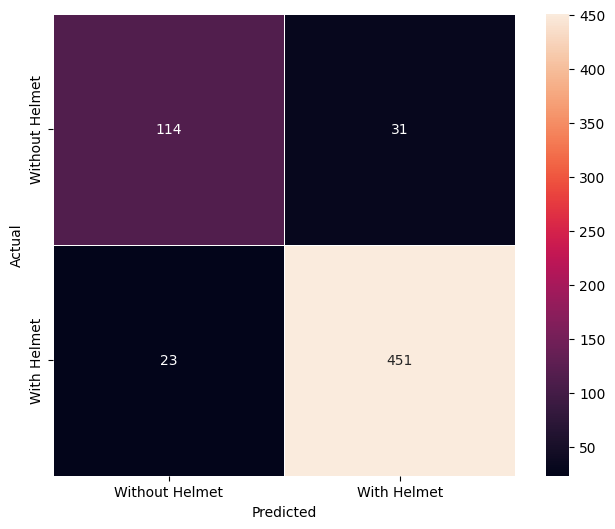

In [21]:
base_model_3 = VGG16(weights='imagenet', include_top=False, input_shape=(200, 200, 3))

for layer in base_model_3.layers:
    layer.trainable = False

model3 = Sequential([
    base_model_3,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model3.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0001), metrics=['accuracy'])

model3.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history3 = model3.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

plot_learning_curves(history3)

print(model_performance_classification(model3, X_train, y_train))
print(model_performance_classification(model3, X_val, y_val))
print_classification_report(model3, X_val, y_val)
plot_confusion_matrix(model3, X_val, y_val)

**Configuration:** loss = `binary_crossentropy`, optimizer = `Adam(learning_rate=1e-4)`, epochs = 15 (with `EarlyStopping`), batch\_size = 32 — identical to Model 2's setup, so any performance difference can be attributed to the added FFNN layer rather than a change in training configuration.

**Observations:**

- Adding a 256-unit Dense (FFNN) layer with Dropout on top of the frozen VGG-16 base gives the model more capacity to combine the pretrained features than Model 2's single output layer.
- Compare this model's validation metrics to Model 2: an improvement suggests the extra FFNN capacity is helping; little or no improvement (or a growing train/validation gap) suggests the extra layer is mainly adding overfitting risk instead.
- Dropout(0.3) is included specifically to counter that added overfitting risk from the extra Dense layer.

#### Visualizing the predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step



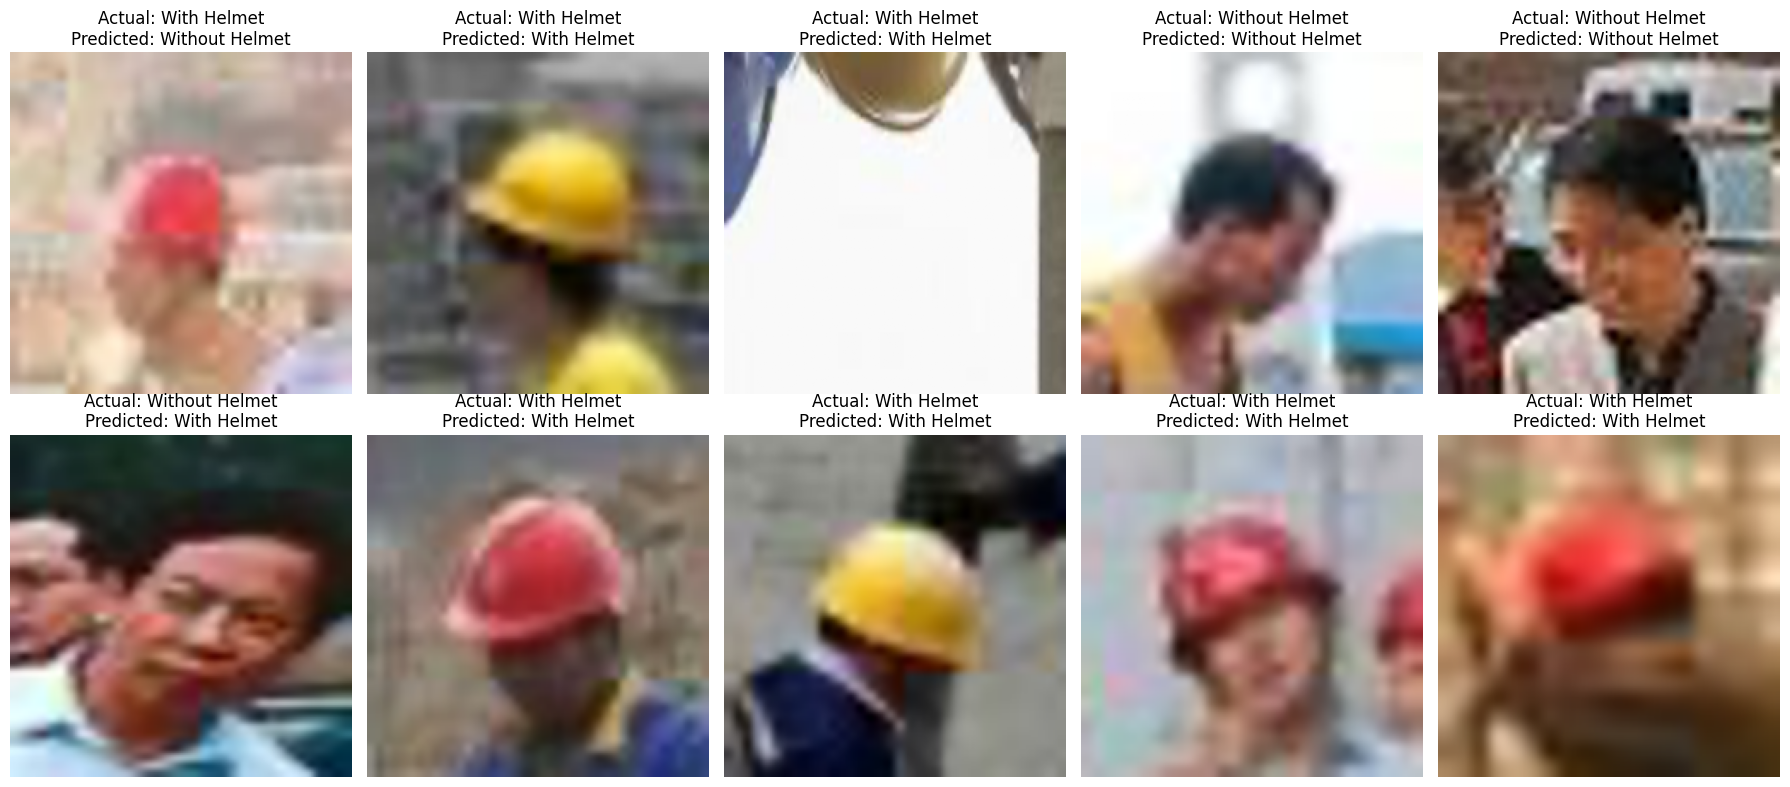

In [22]:
visualize_predictions(model3, X_val, y_val)

## Model 4: Transfer Learning with VGG-16 (Base + FFNN + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

  - Horizontal Flip (should be set to True/False)
  - Vertical Flip (should be set to True/False)
  - Height Shift (should be between 0 and 1)
  - Width Shift (should be between 0 and 1)
  - Rotation (should be between 0 and 180)
  - Shear (should be between 0 and 1)
  - Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 19,433,793 (74.13 MB)

Trainable params: 4,719,105 (18.00 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 40s 431ms/step - accuracy: 0.7117 - loss: 0.5337 - val_accuracy: 0.8853 - val_loss: 0.3204
Epoch 2/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.8750 - loss: 0.3542 - val_accuracy: 0.8885 - val_loss: 0.3174
Epoch 3/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 37s 408ms/step - accuracy: 0.7758 - loss: 0.4332 - val_accuracy: 0.7803 - val_loss: 0.4255
Epoch 4/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.7500 - loss: 0.3089 - val_accuracy: 0.7738 - val_loss: 0.4310
Epoch 5/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 37s 411ms/step - accuracy: 0.8403 - loss: 0.3384 - val_accuracy: 0.7706 - val_loss: 0.4146
Epoch 6/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.8750 - loss: 0.2890 - val_accuracy: 0.7981 - val_loss: 0.3879
Epoch 7/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 37s 410ms/step - accuracy: 0.8329 - loss: 0.3477 - val_accuracy: 0.8869 - val_loss: 0.2626
Epoch 8/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.8750 - loss: 0.4362 - val_accuracy: 0.

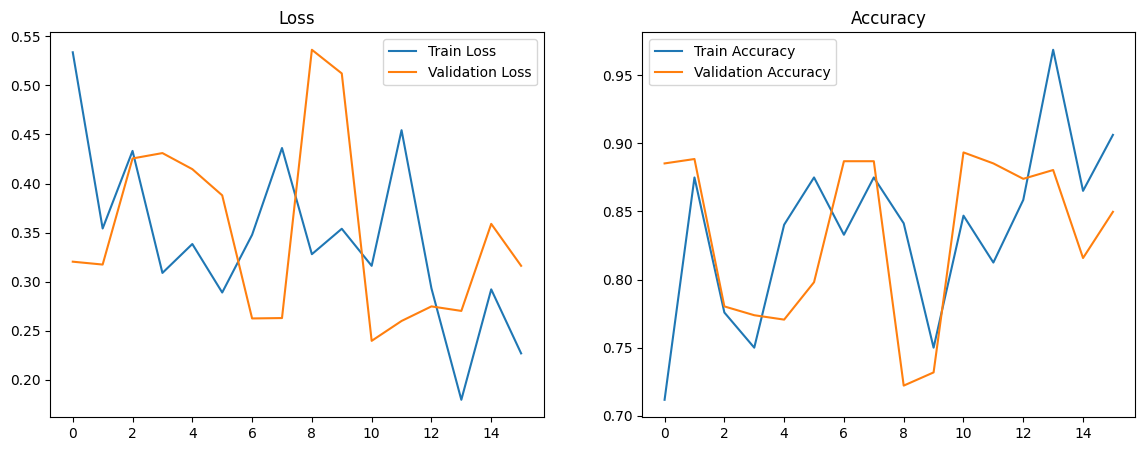

91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 124ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.919986  0.919986   0.919986  0.919986
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.893376  0.893376   0.893376  0.893376
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step
                precision    recall  f1-score   support

Without Helmet       0.74      0.85      0.79       145
   With Helmet       0.95      0.91      0.93       474

      accuracy                           0.89       619
     macro avg       0.84      0.88      0.86       619
  weighted avg       0.90      0.89      0.90       619

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step



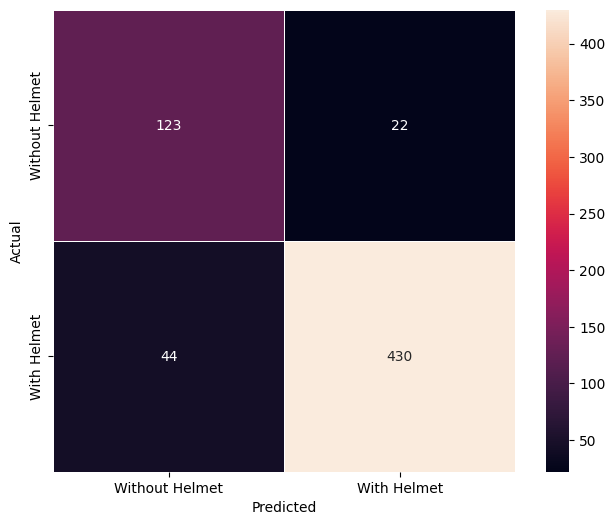

In [23]:
train_datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    shear_range=0.1
)

base_model_4 = VGG16(weights='imagenet', include_top=False, input_shape=(200, 200, 3))

for layer in base_model_4.layers:
    layer.trainable = False

model4 = Sequential([
    base_model_4,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model4.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.0001), metrics=['accuracy'])

model4.summary()

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

batch_size = 32
train_generator = train_datagen.flow(X_train, y_train, batch_size=batch_size, seed=812)

history4 = model4.fit(
    train_generator,
    steps_per_epoch=len(X_train) // batch_size,
    validation_data=(X_val, y_val),
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

plot_learning_curves(history4)

print(model_performance_classification(model4, X_train, y_train))
print(model_performance_classification(model4, X_val, y_val))
print_classification_report(model4, X_val, y_val)
plot_confusion_matrix(model4, X_val, y_val)

**Configuration:** loss = `binary_crossentropy`, optimizer = `Adam(learning_rate=1e-4)`, epochs = 20 (with `EarlyStopping`), batch\_size = 32 — same architecture and optimizer as Model 3, with a few extra epochs allowed since augmented data typically takes slightly longer to converge.

**Observations:**

- Model 4 uses the same architecture as Model 3 (VGG-16 base + FFNN), but the training images are randomly flipped, rotated, shifted and zoomed on the fly — the validation and test sets are left untouched, as required.
- Augmentation is most useful when a model is overfitting (train performance much higher than validation performance); if Model 3 showed a large train/validation gap, this model's gap should be smaller.
- Because the minority "Without Helmet" class already has fewer images, augmentation also effectively gives the model more varied examples of that class to learn from on every epoch.

#### Visualizing the predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step



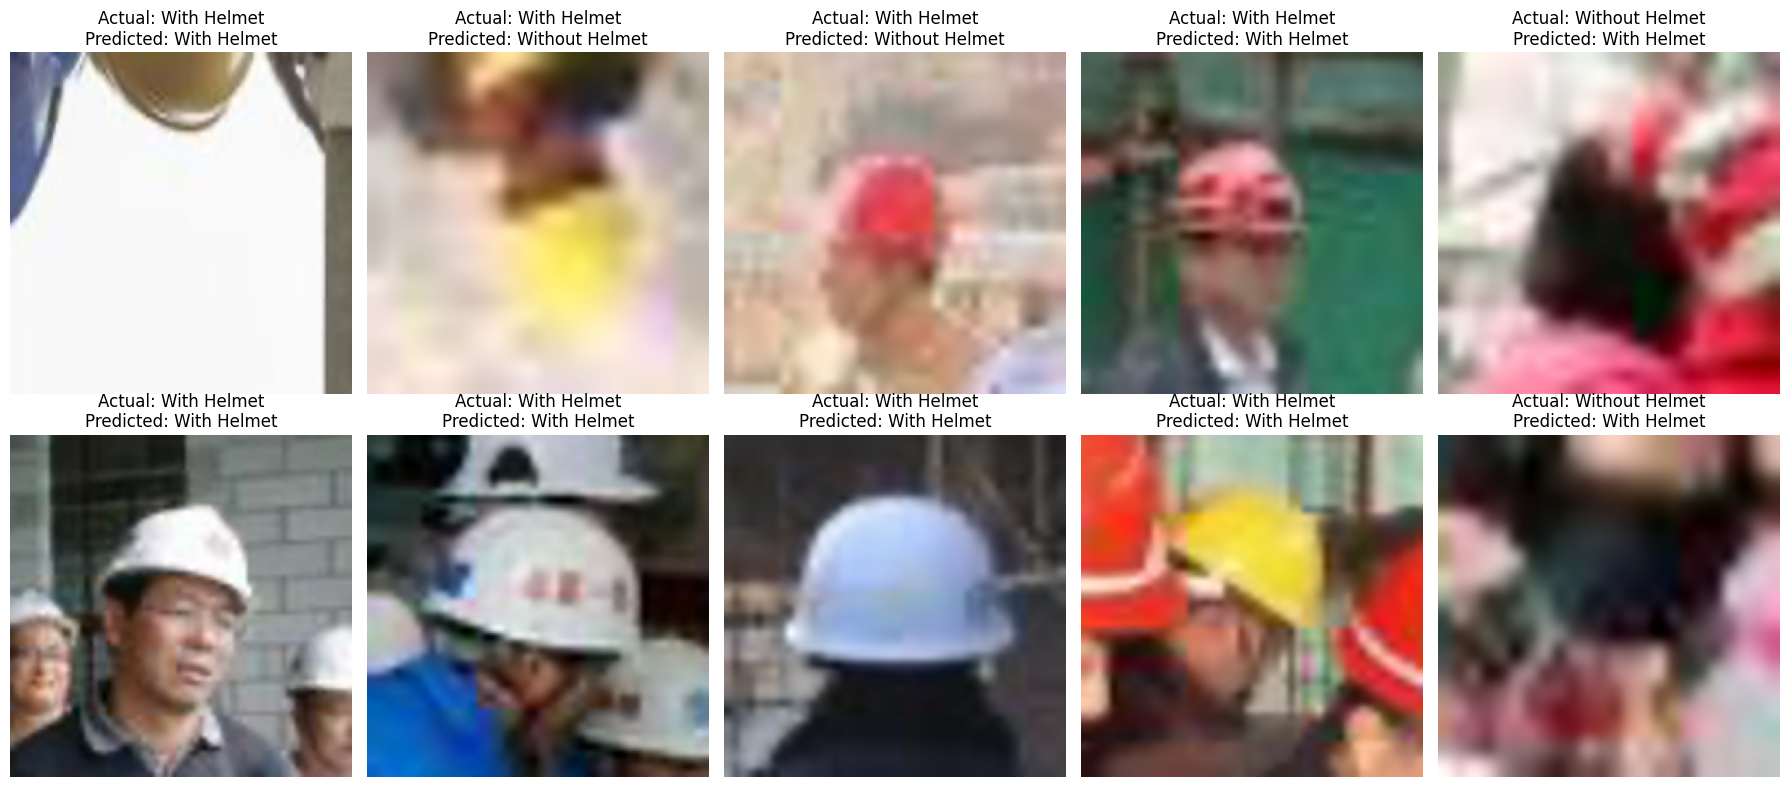

In [24]:
visualize_predictions(model4, X_val, y_val)

# **Model Performance Comparison and Final Model Selection**

91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 122ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step
                                 Model  Train Accuracy  Val Accuracy  \
0                        VGG-16 (Base)        0.903706      0.856220   
1                     CNN from Scratch        0.976100      0.924071   
2  VGG-16 (Base + FFNN + Augmentation)        0.919986      0.893376   
3                 VGG-16 (Base + FFNN)        0.975407      0.912763   

   Val Recall (Without Helmet)  Val Precision (Without Helmet)  \
0                     0.882759                        0.640000   
1                     0.862069                        0.822368   
2                     0.848276                        0.736527   
3                     0.786207                

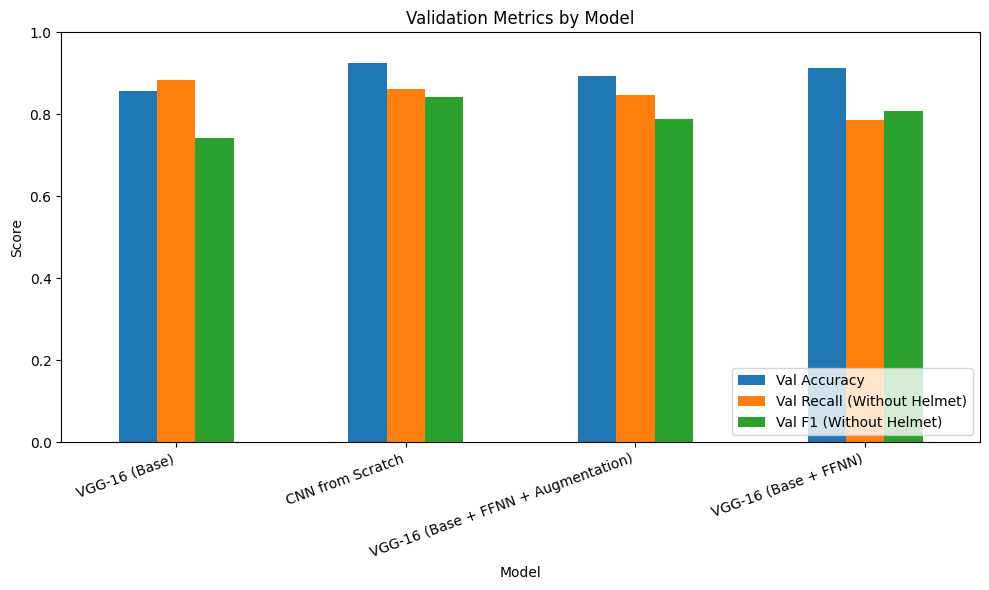

Selected best model based on 'Without Helmet' recall on validation data: VGG-16 (Base)



In [25]:
models_dict = {
    'CNN from Scratch': model1,
    'VGG-16 (Base)': model2,
    'VGG-16 (Base + FFNN)': model3,
    'VGG-16 (Base + FFNN + Augmentation)': model4
}

comparison_rows = []

for name, model in models_dict.items():
    train_pred = model.predict(X_train).reshape(-1) > 0.5
    val_pred = model.predict(X_val).reshape(-1) > 0.5

    # Track overall accuracy plus precision/recall/F1 specifically for the safety-critical
    # "Without Helmet" class (pos_label=0), since that is what the evaluation criterion prioritizes
    row = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, train_pred),
        'Val Accuracy': accuracy_score(y_val, val_pred),
        'Val Recall (Without Helmet)': recall_score(y_val, val_pred, pos_label=0),
        'Val Precision (Without Helmet)': precision_score(y_val, val_pred, pos_label=0),
        'Val F1 (Without Helmet)': f1_score(y_val, val_pred, pos_label=0)
    }
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(by='Val Recall (Without Helmet)', ascending=False).reset_index(drop=True)

print(comparison_df)

# Visualize all four models side by side on the metrics that matter most
comparison_df.set_index('Model')[['Val Accuracy', 'Val Recall (Without Helmet)', 'Val F1 (Without Helmet)']].plot(
    kind='bar', figsize=(10, 6), ylim=(0, 1)
)
plt.ylabel('Score')
plt.title('Validation Metrics by Model')
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

best_model_name = comparison_df.loc[0, 'Model']
best_model = models_dict[best_model_name]

print(f"Selected best model based on 'Without Helmet' recall on validation data: {best_model_name}")

**Model selection reasoning:** The four models above are ranked by **Recall on the "Without Helmet" class**, since — per the evaluation criterion set out earlier — missing a worker who isn't wearing a helmet is the costliest type of error for this business problem. `best_model` is picked automatically as the top-ranked model, but Train/Val Accuracy in the table above should also be checked: a model with high "Without Helmet" recall but very poor overall accuracy (i.e. it is simply over-predicting "Without Helmet" for almost everything) would not be a good real-world choice either. If two models are close on recall, prefer the simpler / cheaper one to run in production (the scratch CNN or VGG-16 Base) over a heavier one, all else being equal.

One more factor worth weighing alongside the metrics: the business objective calls for **real-time** monitoring, and the three VGG-16-based models carry ~14 million frozen parameters they must run on every frame, versus a few hundred thousand for the scratch CNN. If two models are close on 'Without Helmet' recall, the lighter scratch CNN or VGG-16 (Base) model may be the more deployable choice for real-time inference; if the heavier model's recall advantage is large, the added safety benefit likely justifies the extra compute cost.

## Test Performance

Final model: VGG-16 (Base)
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step
   Accuracy    Recall  Precision  F1 Score
0  0.878837  0.878837   0.878837  0.878837
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
                precision    recall  f1-score   support

Without Helmet       0.68      0.90      0.77       144
   With Helmet       0.97      0.87      0.92       475

      accuracy                           0.88       619
     macro avg       0.82      0.88      0.85       619
  weighted avg       0.90      0.88      0.88       619

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step



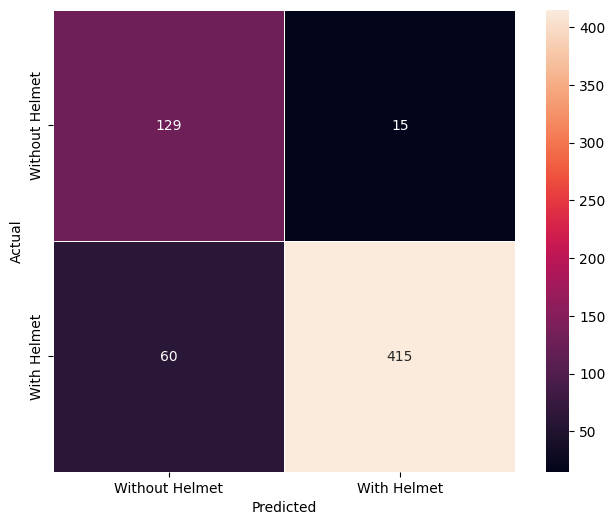

In [26]:
print(f"Final model: {best_model_name}")
print(model_performance_classification(best_model, X_test, y_test))
print_classification_report(best_model, X_test, y_test)
plot_confusion_matrix(best_model, X_test, y_test)

**Observations on final test-set performance:**

- These numbers are the honest, unbiased read on how the selected model would perform on brand-new images, since the test set was never touched during training or model selection.
- Compare this test Recall on the "Without Helmet" class to the validation Recall from the comparison table: a large drop suggests the model (or the model-selection step itself) overfit to the validation set, and a closer match is a good sign the result will hold up in production.
- Use the confusion matrix above to see the concrete trade-off: how many true "Without Helmet" cases are being missed (false negatives, the safety-critical error) versus how many "With Helmet" workers are being flagged unnecessarily (false positives, an efficiency cost but not a safety one).
- Since this model is intended to run in a real-time monitoring pipeline, also weigh its size/inference cost (noted above) alongside these accuracy numbers before recommending it for deployment — the fastest model that clears an acceptable "Without Helmet" recall bar is usually the better production choice over the single highest-scoring one.

# **Actionable Insights & Recommendations**

- **Class imbalance is the biggest risk to watch**: "Without Helmet" images make up only ~23% of the dataset, so a model (or evaluation) that leans on accuracy alone can look good while still missing real safety violations; class weighting and "Without Helmet" recall should stay part of the standard process going forward, not just this one-off project.
- **Transfer learning is the practical path forward**: the VGG-16-based models reuse features learned from millions of images and need far less training data and time than a from-scratch CNN, which matters if SafeGuard later retrains on footage from new sites or camera angles.
- **Data augmentation helps generalization at low cost**: new site footage will always look somewhat different from the training images (lighting, camera angle, PPE color), so augmenting the training data with flips/rotations/shifts/zoom is a cheap way to make the deployed model more robust, and should be kept even as the dataset grows.
- **Recommend a human-in-the-loop for borderline/low-confidence predictions**: rather than fully automating away human oversight, route predictions with low model confidence (probability close to 0.5) to a human reviewer, since a missed "Without Helmet" detection carries real injury risk.
- **Expand the "Without Helmet" training data over time**: collecting more real examples of non-compliant workers, rather than relying on class weighting alone, will likely improve the model further and should be prioritized in the next data collection round.
- **Plan for periodic retraining and monitoring in production**: as sites, cameras, PPE styles and lighting conditions change over time, the model's performance should be periodically re-checked against fresh, labeled samples of real deployment footage, and retrained if "Without Helmet" recall drops.
- **Balance accuracy against real-time inference cost**: the objective calls for real-time monitoring, so the final model choice should weigh not just "Without Helmet" recall but also inference speed and hardware footprint — a slightly less accurate but much lighter model may be the more practical choice for continuous, camera-by-camera deployment across multiple sites.